# Final Analysis

This notebook presents the final analysis of the
construction cost prediction experiment.

## Objectives

- Compare the performance of three machine learning models
- Analyze actual vs predicted construction cost
- Analyze prediction errors
- Examine feature importance
- Investigate overfitting
- Identify critical prediction cases
- Perform further validation
- Summarize research findings and limitations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics  import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [2]:
df = pd.read_csv(
    "../data/raw/construction_cost_dataset_50_projects.csv"
)

df.head()

,Project_ID,Land_Area_sqft,Total_Floor_Area_sqft,Number_of_Floors,Building_Type,Location,Foundation_Type,Project_Duration_months,Material_Cost_crore_BDT,Labour_Cost_crore_BDT,Total_Cost_crore_BDT
0,1,7038,17800,5,Commercial,Dhaka,Pile,16.7,4.10,1.71,7.44
1,2,2060,4300,4,Residential,Other City,Isolated Footing,8.5,0.88,0.38,1.34
2,3,6627,35900,8,Residential,Dhaka,Isolated Footing,28.5,8.00,2.78,11.92
3,4,4912,14200,5,Commercial,Other City,Raft,18.7,4.02,1.19,6.11
4,5,6322,34500,8,Commercial,Other City,Pile,29.4,7.40,2.52,11.21


In [3]:
df.shape

(50, 11)

In [4]:
df["Total_Cost_crore_BDT"].head()

0     7.44
1     1.34
2    11.92
3     6.11
4    11.21
Name: Total_Cost_crore_BDT, dtype: float64

In [5]:
import pandas as pd

from sklearn.model_selection import train_test_split

df = pd.read_csv(
    "../data/raw/construction_cost_dataset_50_projects.csv"
)

df = df.drop(columns=["Project_ID"])

categorical_columns = [
    "Building_Type",
    "Location",
    "Foundation_Type"
]

X = df.drop(columns=["Total_Cost_crore_BDT"])
y = df["Total_Cost_crore_BDT"]

X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True
)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

Linear Regression

In [6]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred_lr = linear_model.predict(X_test)

In [7]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(
    random_state=42
)

tree_model.fit(X_train, y_train)

y_pred_dt = tree_model.predict(X_test)

In [8]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

forest_model.fit(X_train, y_train)

y_pred_rf = forest_model.predict(X_test)

In [9]:
final_results = pd.DataFrame({
    "Actual_Cost": y_test.values,
    "Linear_Regression": y_pred_lr,
    "Decision_Tree": y_pred_dt,
    "Random_Forest": y_pred_rf
})

final_results

,Actual_Cost,Linear_Regression,Decision_Tree,Random_Forest
0,27.92,26.727935,16.99,21.1104
1,11.41,11.981778,10.81,12.1264
2,14.97,15.246964,15.86,15.9054
3,19.25,20.680667,23.23,21.7614
4,3.51,3.307415,4.07,3.7922
5,22.27,21.829422,21.74,20.6979
6,5.40,5.690159,6.17,6.3728
7,16.36,16.302195,14.94,15.8366
8,10.56,9.685386,9.97,10.2389
9,7.86,8.497800,7.28,7.3867


In [10]:
print("Training sample:",len(X_train))
print("Testing sample:",len(X_test))    

Training sample: 40
Testing sample: 10


In [11]:
print(y_test.values)

[27.92 11.41 14.97 19.25  3.51 22.27  5.4  16.36 10.56  7.86]


In [12]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(
    mean_squared_error(y_test, y_pred_lr)
)

r2_lr = r2_score(y_test, y_pred_lr)

In [13]:
results = {
    "Linear Regression": {
        "MAE": mean_absolute_error(y_test, y_pred_lr),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        "R2": r2_score(y_test, y_pred_lr)
    },

    "Decision Tree": {
        "MAE": mean_absolute_error(y_test, y_pred_dt),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_dt)),
        "R2": r2_score(y_test, y_pred_dt)
    },

    "Random Forest": {
        "MAE": mean_absolute_error(y_test, y_pred_rf),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        "R2": r2_score(y_test, y_pred_rf)
    }
}




In [14]:
performance_df = pd.DataFrame(results).T

performance_df

,MAE,RMSE,R2
Linear Regression,0.597501,0.732522,0.989997
Decision Tree,2.085000,3.746274,0.738380
Random Forest,1.511770,2.411732,0.891575


In [15]:
performance_df = pd.DataFrame(results).T
performance_df

,MAE,RMSE,R2
Linear Regression,0.597501,0.732522,0.989997
Decision Tree,2.085000,3.746274,0.738380
Random Forest,1.511770,2.411732,0.891575


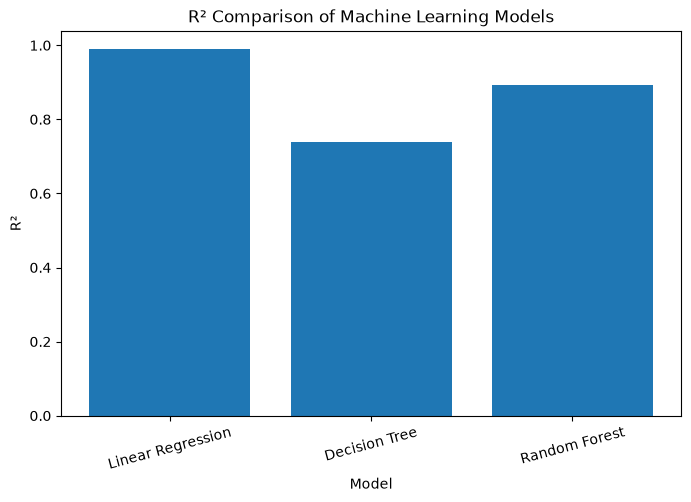

In [16]:
plt.figure(figsize=(8, 5))

plt.bar(
    performance_df.index,
    performance_df["R2"]
)

plt.ylabel("R²")
plt.xlabel("Model")
plt.title("R² Comparison of Machine Learning Models")

plt.xticks(rotation=15)

plt.show()

## Initial Findings

The three machine learning models showed different levels of
prediction performance on the test dataset.

Linear Regression achieved the lowest MAE and RMSE and the highest
R², indicating strong predictive performance on this dataset.

Decision Tree showed the highest prediction error and the lowest R².

Random Forest improved substantially over the single Decision Tree,
suggesting that the ensemble approach provided better generalization
than the individual tree.

However, the reasons behind these performance differences require
further investigation through error analysis, feature importance,
overfitting analysis, and additional validation.

In [17]:
#Actual Vs Predicted Analysis
final_results = pd.DataFrame({
    "Actual_Cost": y_test.values,
    "Linear_Regression": y_pred_lr,
    "Decision_Tree": y_pred_dt,
    "Random_Forest": y_pred_rf
})

final_results


,Actual_Cost,Linear_Regression,Decision_Tree,Random_Forest
0,27.92,26.727935,16.99,21.1104
1,11.41,11.981778,10.81,12.1264
2,14.97,15.246964,15.86,15.9054
3,19.25,20.680667,23.23,21.7614
4,3.51,3.307415,4.07,3.7922
5,22.27,21.829422,21.74,20.6979
6,5.40,5.690159,6.17,6.3728
7,16.36,16.302195,14.94,15.8366
8,10.56,9.685386,9.97,10.2389
9,7.86,8.497800,7.28,7.3867


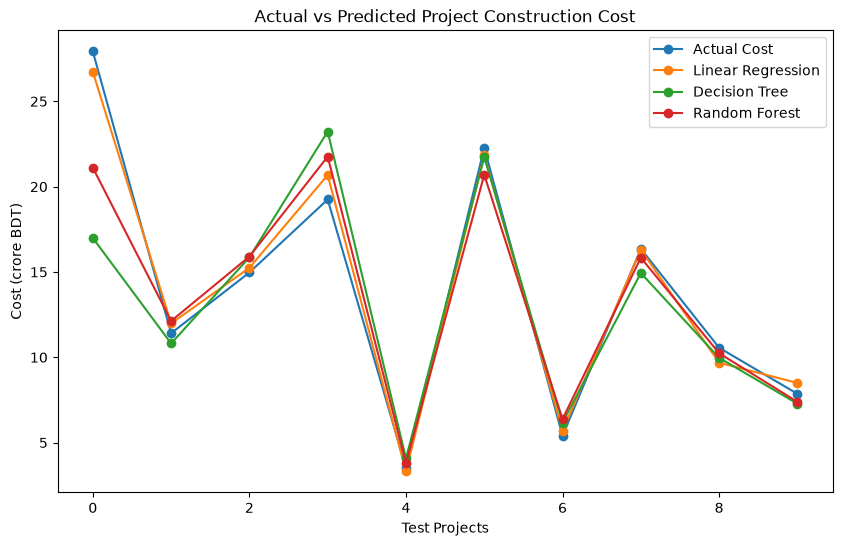

In [18]:
plt.figure(figsize=(10,6))

plt.plot(
    final_results["Actual_Cost"],
    marker='o',
    label='Actual Cost'
)

plt.plot(
    final_results["Linear_Regression"],
    marker='o',
    label='Linear Regression'
)

plt.plot(
    final_results["Decision_Tree"],
    marker='o',
    label='Decision Tree'
)

plt.plot(
    final_results["Random_Forest"],
    marker='o',
    label='Random Forest'
)

plt.xlabel("Test Projects")
plt.ylabel("Cost (crore BDT)")
plt.title("Actual vs Predicted Project Construction Cost")

plt.legend()

plt.show()

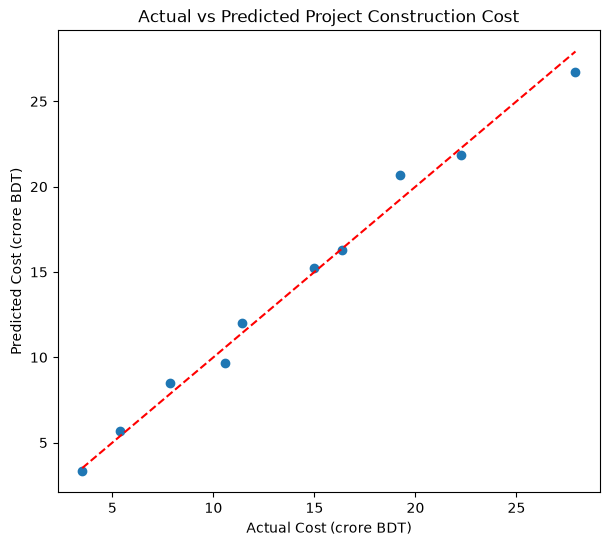

In [19]:
#Actual vs Predicted Scatter Plot
plt.figure(figsize=(7,6))

plt.scatter(
    y_test,
    y_pred_lr
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color='red'
)

plt.xlabel("Actual Cost (crore BDT)")
plt.ylabel("Predicted Cost (crore BDT)")
plt.title("Actual vs Predicted Project Construction Cost")

plt.show()

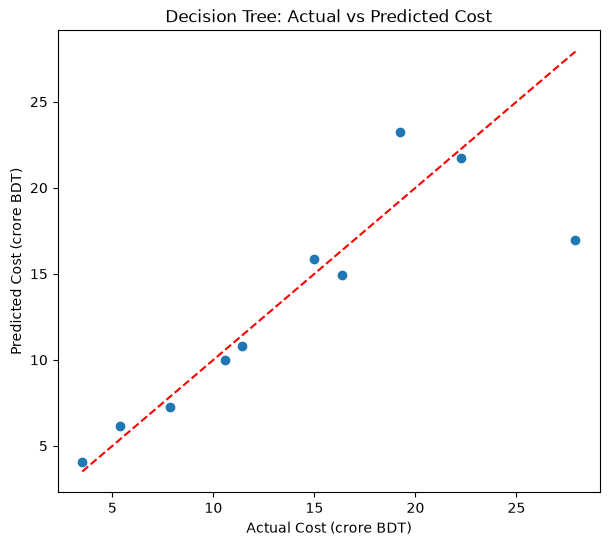

In [20]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_dt
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color='red'
)

plt.xlabel("Actual Cost (crore BDT)")
plt.ylabel("Predicted Cost (crore BDT)")
plt.title("Decision Tree: Actual vs Predicted Cost")

plt.show()

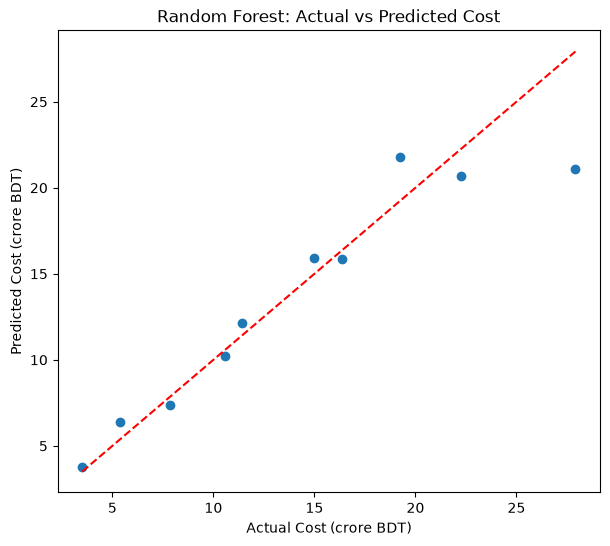

In [21]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_rf
)



plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color='red'
)

plt.xlabel("Actual Cost (crore BDT)")
plt.ylabel("Predicted Cost (crore BDT)")
plt.title("Random Forest: Actual vs Predicted Cost")

plt.show()

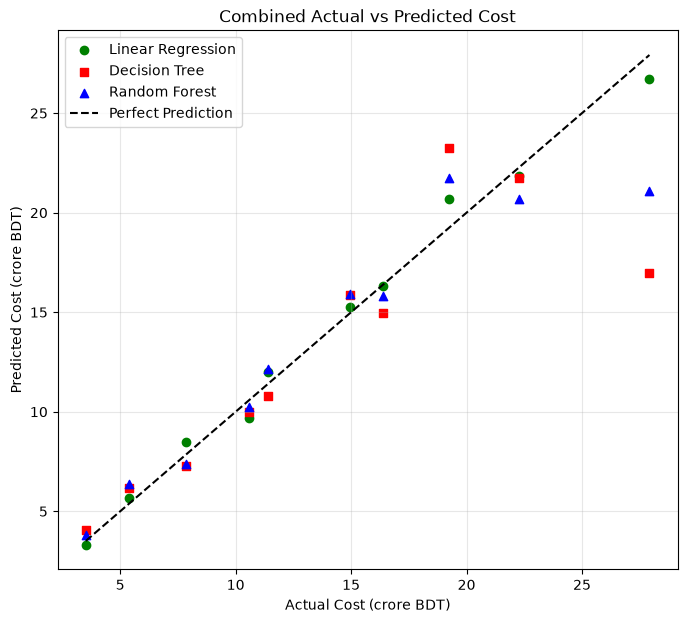

In [22]:
plt.figure(figsize=(8, 7))

# Linear Regression
plt.scatter(
    y_test,
    y_pred_lr,
    color="green",
    marker="o",
    label="Linear Regression"
)

# Decision Tree
plt.scatter(
    y_test,
    y_pred_dt,
    color="red",
    marker="s",
    label="Decision Tree"
)

# Random Forest
plt.scatter(
    y_test,
    y_pred_rf,
    color="blue",
    marker="^",
    label="Random Forest"
)

# Perfect Prediction Line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color="black",
    label="Perfect Prediction"
)

plt.xlabel("Actual Cost (crore BDT)")
plt.ylabel("Predicted Cost (crore BDT)")
plt.title("Combined Actual vs Predicted Cost")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [23]:
final_results["LR_Absolute_Error"] = (
    final_results["Actual_Cost"] - final_results["Linear_Regression"]
).abs()

final_results["DT_Absolute_Error"] = (
    final_results["Actual_Cost"] - final_results["Decision_Tree"]
).abs()

final_results["RF_Absolute_Error"] = (
    final_results["Actual_Cost"] - final_results["Random_Forest"]
).abs()

final_results

,Actual_Cost,Linear_Regression,Decision_Tree,Random_Forest,LR_Absolute_Error,DT_Absolute_Error,RF_Absolute_Error
0,27.92,26.727935,16.99,21.1104,1.192065,10.93,6.8096
1,11.41,11.981778,10.81,12.1264,0.571778,0.60,0.7164
2,14.97,15.246964,15.86,15.9054,0.276964,0.89,0.9354
3,19.25,20.680667,23.23,21.7614,1.430667,3.98,2.5114
4,3.51,3.307415,4.07,3.7922,0.202585,0.56,0.2822
5,22.27,21.829422,21.74,20.6979,0.440578,0.53,1.5721
6,5.40,5.690159,6.17,6.3728,0.290159,0.77,0.9728
7,16.36,16.302195,14.94,15.8366,0.057805,1.42,0.5234
8,10.56,9.685386,9.97,10.2389,0.874614,0.59,0.3211
9,7.86,8.497800,7.28,7.3867,0.637800,0.58,0.4733


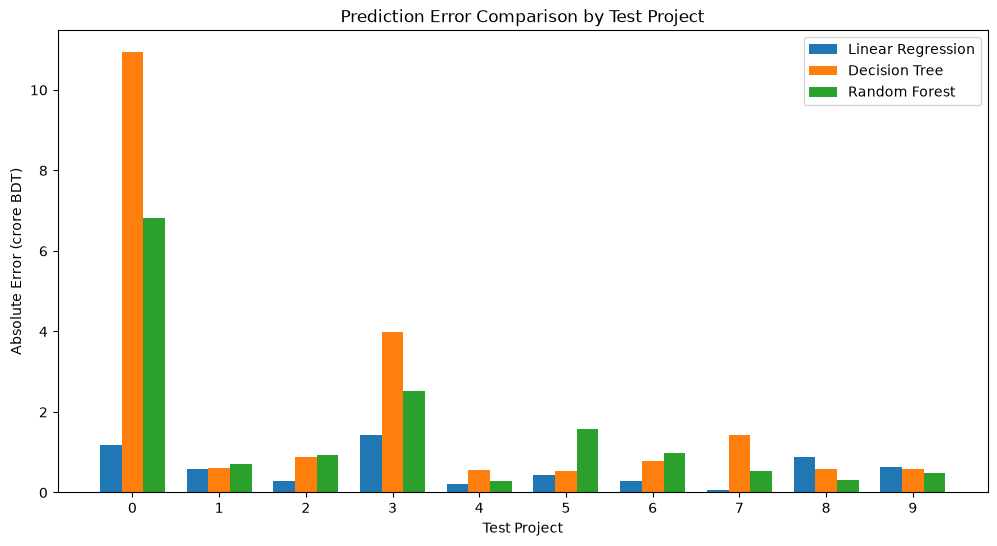

In [24]:
import numpy as np

x = np.arange(len(final_results))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    final_results["LR_Absolute_Error"],
    width,
    label="Linear Regression"
)

plt.bar(
    x,
    final_results["DT_Absolute_Error"],
    width,
    label="Decision Tree"
)

plt.bar(
    x + width,
    final_results["RF_Absolute_Error"],
    width,
    label="Random Forest"
)

plt.xlabel("Test Project")
plt.ylabel("Absolute Error (crore BDT)")
plt.title("Prediction Error Comparison by Test Project")

plt.xticks(x, final_results.index)

plt.legend()

plt.show()

In [25]:
final_results.loc[
    final_results["LR_Absolute_Error"].idxmax()
]

Actual_Cost          19.250000
Linear_Regression    20.680667
Decision_Tree        23.230000
Random_Forest        21.761400
LR_Absolute_Error     1.430667
DT_Absolute_Error     3.980000
RF_Absolute_Error     2.511400
Name: 3, dtype: float64

In [26]:
final_results.loc[
    final_results["DT_Absolute_Error"].idxmax()
]

Actual_Cost          27.920000
Linear_Regression    26.727935
Decision_Tree        16.990000
Random_Forest        21.110400
LR_Absolute_Error     1.192065
DT_Absolute_Error    10.930000
RF_Absolute_Error     6.809600
Name: 0, dtype: float64

In [27]:
final_results.loc[
    final_results["RF_Absolute_Error"].idxmax()
]

Actual_Cost          27.920000
Linear_Regression    26.727935
Decision_Tree        16.990000
Random_Forest        21.110400
LR_Absolute_Error     1.192065
DT_Absolute_Error    10.930000
RF_Absolute_Error     6.809600
Name: 0, dtype: float64

In [28]:
X_test_original = X_test.copy()

X_test_original

,Land_Area_sqft,Total_Floor_Area_sqft,Number_of_Floors,Project_Duration_months,Material_Cost_crore_BDT,Labour_Cost_crore_BDT,Building_Type_Residential,Location_Dhaka,Location_Other City,Foundation_Type_Pile,Foundation_Type_Raft
13,8178,68900,12,44.9,16.97,6.85,False,False,False,True,False
39,6462,30500,8,24.2,8.04,2.63,True,False,False,False,True
30,6319,39400,10,33.3,9.83,3.91,True,True,False,False,False
45,8857,58400,11,43.0,13.85,5.08,True,False,True,False,True
17,2057,9500,9,14.2,2.27,0.86,True,False,False,False,False
48,8071,48800,10,38.2,14.90,3.89,False,False,False,False,True
26,6888,17800,5,16.7,3.91,1.20,True,False,True,False,True
25,7667,38100,9,31.0,10.12,3.91,False,True,False,False,False
32,6884,29100,6,27.5,5.75,2.79,True,True,False,True,False
19,7153,18400,5,17.4,5.03,1.38,False,True,False,True,False


In [29]:
test_size=0.20
random_state=42

test_project_data = df.loc[X_test.index].copy()

test_project_data

,Land_Area_sqft,Total_Floor_Area_sqft,Number_of_Floors,Building_Type,Location,Foundation_Type,Project_Duration_months,Material_Cost_crore_BDT,Labour_Cost_crore_BDT,Total_Cost_crore_BDT
13,8178,68900,12,Commercial,Chattogram,Pile,44.9,16.97,6.85,27.92
39,6462,30500,8,Residential,Chattogram,Raft,24.2,8.04,2.63,11.41
30,6319,39400,10,Residential,Dhaka,Isolated Footing,33.3,9.83,3.91,14.97
45,8857,58400,11,Residential,Other City,Raft,43.0,13.85,5.08,19.25
17,2057,9500,9,Residential,Chattogram,Isolated Footing,14.2,2.27,0.86,3.51
48,8071,48800,10,Commercial,Chattogram,Raft,38.2,14.90,3.89,22.27
26,6888,17800,5,Residential,Other City,Raft,16.7,3.91,1.20,5.40
25,7667,38100,9,Commercial,Dhaka,Isolated Footing,31.0,10.12,3.91,16.36
32,6884,29100,6,Residential,Dhaka,Pile,27.5,5.75,2.79,10.56
19,7153,18400,5,Commercial,Dhaka,Pile,17.4,5.03,1.38,7.86


In [30]:
test_project_data.index

Index([13, 39, 30, 45, 17, 48, 26, 25, 32, 19], dtype='int64')

In [31]:
%whos

Variable                Type                     Data/Info
----------------------------------------------------------
DecisionTreeRegressor   ABCMeta                  <class 'sklearn.tree._cla<...>s.DecisionTreeRegressor'>
LinearRegression        ABCMeta                  <class 'sklearn.linear_mo<...>._base.LinearRegression'>
RandomForestRegressor   ABCMeta                  <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
X                       DataFrame                Shape: (50, 9)
X_encoded               DataFrame                Shape: (50, 11)
X_test                  DataFrame                Shape: (10, 11)
X_test_original         DataFrame                Shape: (10, 11)
X_train                 DataFrame                Shape: (40, 11)
categorical_columns     list                     n=3
df                      DataFrame                Shape: (50, 10)
final_results           DataFrame                Shape: (10, 7)
forest_model            RandomForestRegressor    RandomForest

In [32]:
feature_importance = forest_model.feature_importances_

feature_importance

array([0.00580641, 0.16791056, 0.00231452, 0.07896697, 0.54142972,
       0.19616412, 0.00054817, 0.0014614 , 0.00222453, 0.00093554,
       0.00223805])

In [33]:
feature_names = X_train.columns

feature_names

Index(['Land_Area_sqft', 'Total_Floor_Area_sqft', 'Number_of_Floors',
       'Project_Duration_months', 'Material_Cost_crore_BDT',
       'Labour_Cost_crore_BDT', 'Building_Type_Residential', 'Location_Dhaka',
       'Location_Other City', 'Foundation_Type_Pile', 'Foundation_Type_Raft'],
      dtype='str')

In [34]:
feature_importance_df = pd.DataFrame({
    "Feature" : feature_names,
    "Importance" : feature_importance
})

feature_importance_df

,Feature,Importance
0,Land_Area_sqft,0.005806
1,Total_Floor_Area_sqft,0.167911
2,Number_of_Floors,0.002315
3,Project_Duration_months,0.078967
4,Material_Cost_crore_BDT,0.541430
5,Labour_Cost_crore_BDT,0.196164
6,Building_Type_Residential,0.000548
7,Location_Dhaka,0.001461
8,Location_Other City,0.002225
9,Foundation_Type_Pile,0.000936


In [35]:

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending = False
)

feature_importance_df


,Feature,Importance
4,Material_Cost_crore_BDT,0.541430
5,Labour_Cost_crore_BDT,0.196164
1,Total_Floor_Area_sqft,0.167911
3,Project_Duration_months,0.078967
0,Land_Area_sqft,0.005806
2,Number_of_Floors,0.002315
10,Foundation_Type_Raft,0.002238
8,Location_Other City,0.002225
7,Location_Dhaka,0.001461
9,Foundation_Type_Pile,0.000936


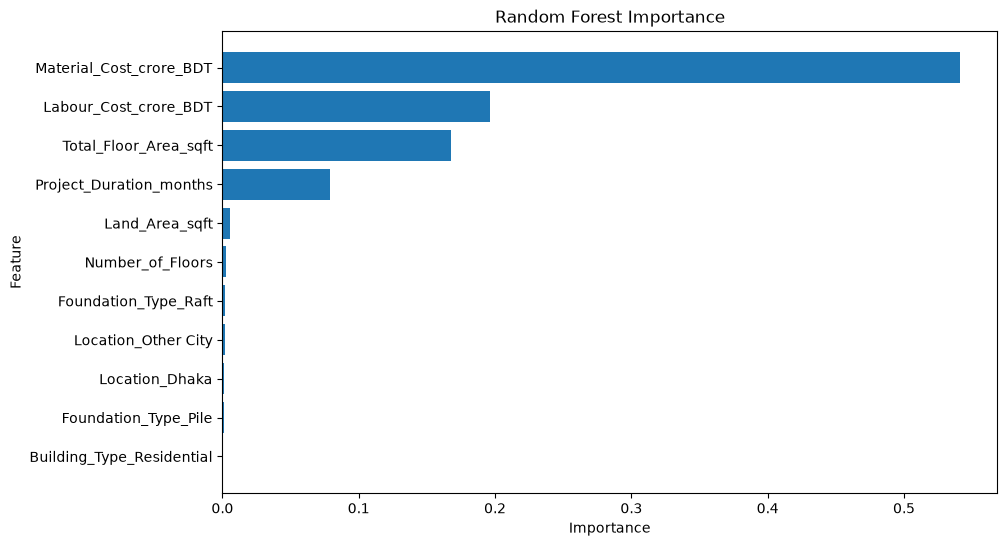

In [36]:
plt.figure(figsize=(10,6))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Importance")

plt.gca().invert_yaxis()

plt.show()

In [37]:
final_results

,Actual_Cost,Linear_Regression,Decision_Tree,Random_Forest,LR_Absolute_Error,DT_Absolute_Error,RF_Absolute_Error
0,27.92,26.727935,16.99,21.1104,1.192065,10.93,6.8096
1,11.41,11.981778,10.81,12.1264,0.571778,0.60,0.7164
2,14.97,15.246964,15.86,15.9054,0.276964,0.89,0.9354
3,19.25,20.680667,23.23,21.7614,1.430667,3.98,2.5114
4,3.51,3.307415,4.07,3.7922,0.202585,0.56,0.2822
5,22.27,21.829422,21.74,20.6979,0.440578,0.53,1.5721
6,5.40,5.690159,6.17,6.3728,0.290159,0.77,0.9728
7,16.36,16.302195,14.94,15.8366,0.057805,1.42,0.5234
8,10.56,9.685386,9.97,10.2389,0.874614,0.59,0.3211
9,7.86,8.497800,7.28,7.3867,0.637800,0.58,0.4733


06. Critical Prediction Conditions

In [38]:
final_results["RF_Absolute_Error"] = (
    final_results["Actual_Cost"] - final_results["Random_Forest"]
).abs()

final_results.sort_values(
    by="RF_Absolute_Error",
    ascending=False
)


,Actual_Cost,Linear_Regression,Decision_Tree,Random_Forest,LR_Absolute_Error,DT_Absolute_Error,RF_Absolute_Error
0,27.92,26.727935,16.99,21.1104,1.192065,10.93,6.8096
3,19.25,20.680667,23.23,21.7614,1.430667,3.98,2.5114
5,22.27,21.829422,21.74,20.6979,0.440578,0.53,1.5721
6,5.40,5.690159,6.17,6.3728,0.290159,0.77,0.9728
2,14.97,15.246964,15.86,15.9054,0.276964,0.89,0.9354
1,11.41,11.981778,10.81,12.1264,0.571778,0.60,0.7164
7,16.36,16.302195,14.94,15.8366,0.057805,1.42,0.5234
9,7.86,8.497800,7.28,7.3867,0.637800,0.58,0.4733
8,10.56,9.685386,9.97,10.2389,0.874614,0.59,0.3211
4,3.51,3.307415,4.07,3.7922,0.202585,0.56,0.2822


In [39]:
X_test_original

,Land_Area_sqft,Total_Floor_Area_sqft,Number_of_Floors,Project_Duration_months,Material_Cost_crore_BDT,Labour_Cost_crore_BDT,Building_Type_Residential,Location_Dhaka,Location_Other City,Foundation_Type_Pile,Foundation_Type_Raft
13,8178,68900,12,44.9,16.97,6.85,False,False,False,True,False
39,6462,30500,8,24.2,8.04,2.63,True,False,False,False,True
30,6319,39400,10,33.3,9.83,3.91,True,True,False,False,False
45,8857,58400,11,43.0,13.85,5.08,True,False,True,False,True
17,2057,9500,9,14.2,2.27,0.86,True,False,False,False,False
48,8071,48800,10,38.2,14.90,3.89,False,False,False,False,True
26,6888,17800,5,16.7,3.91,1.20,True,False,True,False,True
25,7667,38100,9,31.0,10.12,3.91,False,True,False,False,False
32,6884,29100,6,27.5,5.75,2.79,True,True,False,True,False
19,7153,18400,5,17.4,5.03,1.38,False,True,False,True,False


In [40]:
critical_analysis = X_test_original.copy()

critical_analysis["Actual_Cost"] = final_results["Actual_Cost"].values

critical_analysis["Random_Forest_Predicted"] = (
    final_results["Random_Forest"].values
)

critical_analysis["RF_Absolute_Error"] = (
    final_results["RF_Absolute_Error"].values
)

critical_analysis

,Land_Area_sqft,Total_Floor_Area_sqft,Number_of_Floors,Project_Duration_months,Material_Cost_crore_BDT,Labour_Cost_crore_BDT,Building_Type_Residential,Location_Dhaka,Location_Other City,Foundation_Type_Pile,Foundation_Type_Raft,Actual_Cost,Random_Forest_Predicted,RF_Absolute_Error
13,8178,68900,12,44.9,16.97,6.85,False,False,False,True,False,27.92,21.1104,6.8096
39,6462,30500,8,24.2,8.04,2.63,True,False,False,False,True,11.41,12.1264,0.7164
30,6319,39400,10,33.3,9.83,3.91,True,True,False,False,False,14.97,15.9054,0.9354
45,8857,58400,11,43.0,13.85,5.08,True,False,True,False,True,19.25,21.7614,2.5114
17,2057,9500,9,14.2,2.27,0.86,True,False,False,False,False,3.51,3.7922,0.2822
48,8071,48800,10,38.2,14.90,3.89,False,False,False,False,True,22.27,20.6979,1.5721
26,6888,17800,5,16.7,3.91,1.20,True,False,True,False,True,5.40,6.3728,0.9728
25,7667,38100,9,31.0,10.12,3.91,False,True,False,False,False,16.36,15.8366,0.5234
32,6884,29100,6,27.5,5.75,2.79,True,True,False,True,False,10.56,10.2389,0.3211
19,7153,18400,5,17.4,5.03,1.38,False,True,False,True,False,7.86,7.3867,0.4733


In [41]:
critical_analysis = critical_analysis.sort_values(
    by="RF_Absolute_Error",
    ascending=False
)

critical_analysis

,Land_Area_sqft,Total_Floor_Area_sqft,Number_of_Floors,Project_Duration_months,Material_Cost_crore_BDT,Labour_Cost_crore_BDT,Building_Type_Residential,Location_Dhaka,Location_Other City,Foundation_Type_Pile,Foundation_Type_Raft,Actual_Cost,Random_Forest_Predicted,RF_Absolute_Error
13,8178,68900,12,44.9,16.97,6.85,False,False,False,True,False,27.92,21.1104,6.8096
45,8857,58400,11,43.0,13.85,5.08,True,False,True,False,True,19.25,21.7614,2.5114
48,8071,48800,10,38.2,14.90,3.89,False,False,False,False,True,22.27,20.6979,1.5721
26,6888,17800,5,16.7,3.91,1.20,True,False,True,False,True,5.40,6.3728,0.9728
30,6319,39400,10,33.3,9.83,3.91,True,True,False,False,False,14.97,15.9054,0.9354
39,6462,30500,8,24.2,8.04,2.63,True,False,False,False,True,11.41,12.1264,0.7164
25,7667,38100,9,31.0,10.12,3.91,False,True,False,False,False,16.36,15.8366,0.5234
19,7153,18400,5,17.4,5.03,1.38,False,True,False,True,False,7.86,7.3867,0.4733
32,6884,29100,6,27.5,5.75,2.79,True,True,False,True,False,10.56,10.2389,0.3211
17,2057,9500,9,14.2,2.27,0.86,True,False,False,False,False,3.51,3.7922,0.2822


In [42]:
top_error_cases = critical_analysis.head(3)

top_error_cases

,Land_Area_sqft,Total_Floor_Area_sqft,Number_of_Floors,Project_Duration_months,Material_Cost_crore_BDT,Labour_Cost_crore_BDT,Building_Type_Residential,Location_Dhaka,Location_Other City,Foundation_Type_Pile,Foundation_Type_Raft,Actual_Cost,Random_Forest_Predicted,RF_Absolute_Error
13,8178,68900,12,44.9,16.97,6.85,False,False,False,True,False,27.92,21.1104,6.8096
45,8857,58400,11,43.0,13.85,5.08,True,False,True,False,True,19.25,21.7614,2.5114
48,8071,48800,10,38.2,14.90,3.89,False,False,False,False,True,22.27,20.6979,1.5721


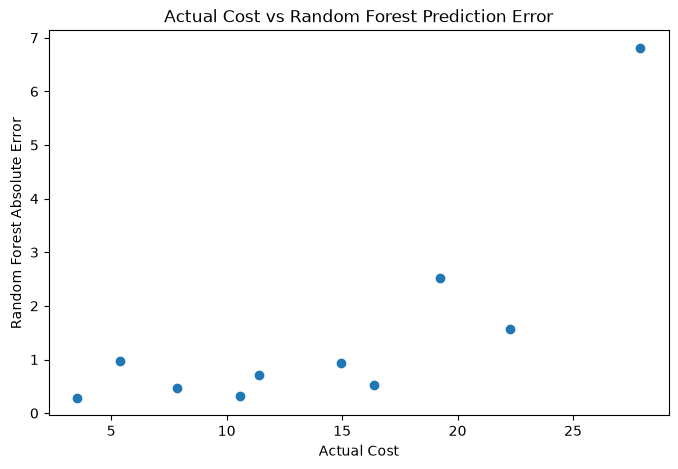

In [43]:
plt.figure(figsize=(8, 5))

plt.scatter(
    critical_analysis["Actual_Cost"],
    critical_analysis["RF_Absolute_Error"]
)

plt.xlabel("Actual Cost")
plt.ylabel("Random Forest Absolute Error")
plt.title("Actual Cost vs Random Forest Prediction Error")

plt.show()

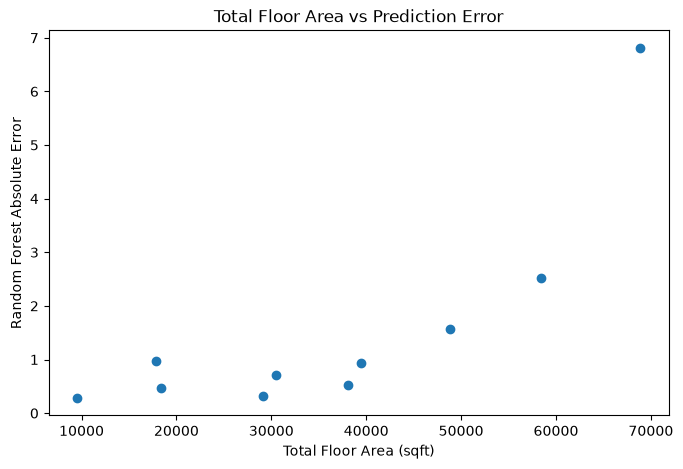

In [44]:
plt.figure(figsize=(8, 5))

plt.scatter(
    critical_analysis["Total_Floor_Area_sqft"],
    critical_analysis["RF_Absolute_Error"]
)

plt.xlabel("Total Floor Area (sqft)")
plt.ylabel("Random Forest Absolute Error")
plt.title("Total Floor Area vs Prediction Error")

plt.show()

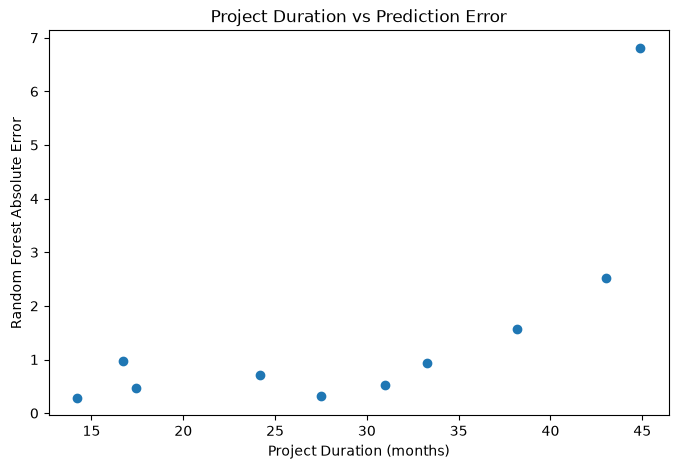

In [45]:
plt.figure(figsize=(8, 5))

plt.scatter(
    critical_analysis["Project_Duration_months"],
    critical_analysis["RF_Absolute_Error"]
)

plt.xlabel("Project Duration (months)")
plt.ylabel("Random Forest Absolute Error")
plt.title("Project Duration vs Prediction Error")

plt.show()

07. Training vs Test / Overfitting

In [46]:
training_test_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Training_R2": [
        0.99410820409847,
        1.0,
        0.9929909401937378
    ],
    "Testing_R2": [
        0.9899974069326832,
        0.7383804993903528,
        0.8915750608598545
    ]
})

training_test_results

,Model,Training_R2,Testing_R2
0,Linear Regression,0.994108,0.989997
1,Decision Tree,1.000000,0.738380
2,Random Forest,0.992991,0.891575


In [47]:
training_test_results["R2_Gap"] = (
    training_test_results["Training_R2"]
    - training_test_results["Testing_R2"]
)

training_test_results

,Model,Training_R2,Testing_R2,R2_Gap
0,Linear Regression,0.994108,0.989997,0.004111
1,Decision Tree,1.000000,0.738380,0.261620
2,Random Forest,0.992991,0.891575,0.101416


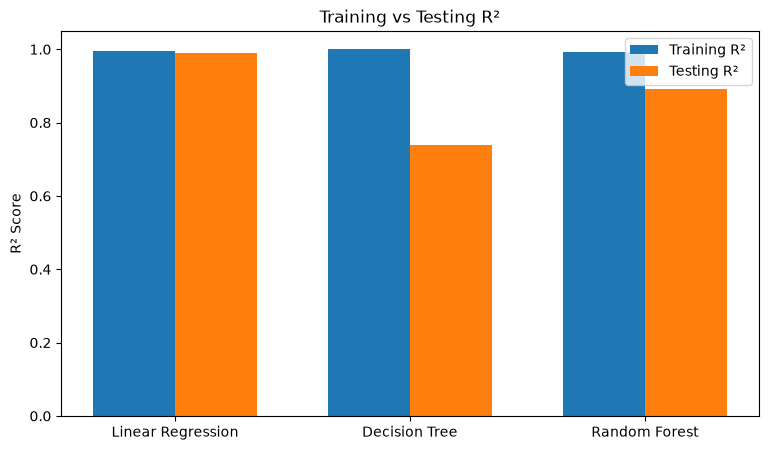

In [48]:
plt.figure(figsize=(9, 5))

x = np.arange(len(training_test_results["Model"]))
width = 0.35

plt.bar(
    x - width/2,
    training_test_results["Training_R2"],
    width,
    label="Training R²"
)

plt.bar(
    x + width/2,
    training_test_results["Testing_R2"],
    width,
    label="Testing R²"
)

plt.xticks(x, training_test_results["Model"])
plt.ylabel("R² Score")
plt.title("Training vs Testing R²")
plt.legend()

plt.show()

### Training vs Testing Analysis

The training and testing R² scores were compared to assess model
generalization and identify potential overfitting.

Linear Regression achieved a training R² of approximately 0.994
and a testing R² of approximately 0.990, indicating a small
training-testing performance gap.

Decision Tree achieved a training R² of 1.000 but a testing R²
of approximately 0.738, indicating a substantial performance gap
and a potential overfitting issue.

Random Forest achieved a training R² of approximately 0.993 and
a testing R² of approximately 0.892. Its training-testing gap was
smaller than that of the Decision Tree.

These observations are specific to the current dataset and
train-test split.

In [49]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [50]:
kf


KFold(n_splits=5, random_state=42, shuffle=True)

In [51]:
lr_cv_scores = cross_val_score(
    linear_model,
    X_train,
    y_train,
    cv=kf,
    scoring="r2"
)

In [52]:
lr_cv_scores

array([0.99013212, 0.97984033, 0.97103605, 0.98739777, 0.94471179])

In [53]:
print("Linear Regression")
print("Fold R² Scores:", lr_cv_scores)
print("Mean R²:", lr_cv_scores.mean())
print("Std R²:", lr_cv_scores.std())

Linear Regression
Fold R² Scores: [0.99013212 0.97984033 0.97103605 0.98739777 0.94471179]
Mean R²: 0.9746236119340155
Std R²: 0.016361509641744786


In [54]:
dt_cv_scores = cross_val_score(
    tree_model,
    X_train,
    y_train,
    cv=kf,
    scoring="r2"
)

In [55]:
print("Decision Tree")
print("Fold R² Scores:", dt_cv_scores)
print("Mean R²:", dt_cv_scores.mean())
print("Std R²:", dt_cv_scores.std())

Decision Tree
Fold R² Scores: [0.96237703 0.82774204 0.8263151  0.9784418  0.93524629]
Mean R²: 0.9060244510163882
Std R²: 0.06596289514130278


In [56]:
rf_cv_scores = cross_val_score(
    forest_model,
    X_train,
    y_train,
    cv=kf,
    scoring="r2"
)

In [57]:
print("Random Forest")
print("Fold R² Scores:", rf_cv_scores)
print("Mean R²:", rf_cv_scores.mean())
print("Std R²:", rf_cv_scores.std())

Random Forest
Fold R² Scores: [0.98728554 0.8456917  0.90541995 0.91831166 0.97834435]
Mean R²: 0.9270106402103234
Std R²: 0.05181276643023176


In [58]:
cv_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Mean_R2": [
        lr_cv_scores.mean(),
        dt_cv_scores.mean(),
        rf_cv_scores.mean()
    ],
    "Std_R2": [
        lr_cv_scores.std(),
        dt_cv_scores.std(),
        rf_cv_scores.std()
    ]
})

cv_results

,Model,Mean_R2,Std_R2
0,Linear Regression,0.974624,0.016362
1,Decision Tree,0.906024,0.065963
2,Random Forest,0.927011,0.051813


09. Feature Ablation Experiment

In [63]:
rf_baseline = RandomForestRegressor(
    random_state=42
)

rf_baseline.fit(X_train, y_train)

# baseline_pred = rf_baseline.predict(X_test)
baseline_pred = rf_baseline.predict(X_test)

baseline_r2 = r2_score(
    y_test,
    baseline_pred
)

baseline_r2

0.8915750608598545

In [67]:
X_train_no_material = X_train.drop(
    columns=["Material_Cost_crore_BDT"]
)

X_test_no_material = X_test.drop(
    columns=["Material_Cost_crore_BDT"]
)

In [68]:
rf_no_material = RandomForestRegressor(
    random_state=42
)

rf_no_material.fit(
    X_train_no_material,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [70]:
pred_no_material = rf_no_material.predict(
    X_test_no_material
)

r2_no_material = r2_score(
    y_test,
    pred_no_material
)

r2_no_material

0.8911209682496043

In [71]:
print("Baseline R²:", baseline_r2)
print("Without Material Cost R²:", r2_no_material)

Baseline R²: 0.8915750608598545
Without Material Cost R²: 0.8911209682496043


In [72]:
material_drop = baseline_r2 - r2_no_material

material_drop

0.00045409261025020076

In [73]:
X_train_no_labour = X_train.drop(
    columns=["Labour_Cost_crore_BDT"]
)

X_test_no_labour = X_test.drop(
    columns=["Labour_Cost_crore_BDT"]
)

In [74]:
rf_no_labour = RandomForestRegressor(
    random_state=42
)

rf_no_labour.fit(
    X_train_no_labour,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [75]:
pred_no_labour = rf_no_labour.predict(
    X_test_no_labour
)

In [76]:
r2_no_labour = r2_score(
    y_test,
    pred_no_labour
)

r2_no_labour

0.8836127026003129

In [77]:
X_train_no_floor = X_train.drop(
    columns=["Total_Floor_Area_sqft"]
)

X_test_no_floor = X_test.drop(
    columns=["Total_Floor_Area_sqft"]
)

In [78]:
rf_no_floor = RandomForestRegressor(
    random_state=42
)

rf_no_floor.fit(
    X_train_no_floor,
    y_train
)

pred_no_floor = rf_no_floor.predict(
    X_test_no_floor
)

r2_no_floor = r2_score(
    y_test,
    pred_no_floor
)

r2_no_floor

0.8821628000195134

In [79]:
X_train_no_duration = X_train.drop(
    columns=["Project_Duration_months"]
)

X_test_no_duration = X_test.drop(
    columns=["Project_Duration_months"]
)

In [80]:
rf_no_duration = RandomForestRegressor(
    random_state=42
)

rf_no_duration.fit(
    X_train_no_duration,
    y_train
)

pred_no_duration = rf_no_duration.predict(
    X_test_no_duration
)

r2_no_duration = r2_score(
    y_test,
    pred_no_duration
)

r2_no_duration

0.8918035818046609

In [81]:
ablation_results = pd.DataFrame({
    "Experiment": [
        "All Features",
        "Without Material Cost",
        "Without Labour Cost",
        "Without Total Floor Area",
        "Without Project Duration"
    ],
    "R2": [
        baseline_r2,
        r2_no_material,
        r2_no_labour,
        r2_no_floor,
        r2_no_duration
    ]
})

ablation_results

,Experiment,R2
0,All Features,0.891575
1,Without Material Cost,0.891121
2,Without Labour Cost,0.883613
3,Without Total Floor Area,0.882163
4,Without Project Duration,0.891804


In [82]:
ablation_results["R2_Drop"] = (
    baseline_r2 - ablation_results["R2"]
)

ablation_results

,Experiment,R2,R2_Drop
0,All Features,0.891575,0.000000
1,Without Material Cost,0.891121,0.000454
2,Without Labour Cost,0.883613,0.007962
3,Without Total Floor Area,0.882163,0.009412
4,Without Project Duration,0.891804,-0.000229


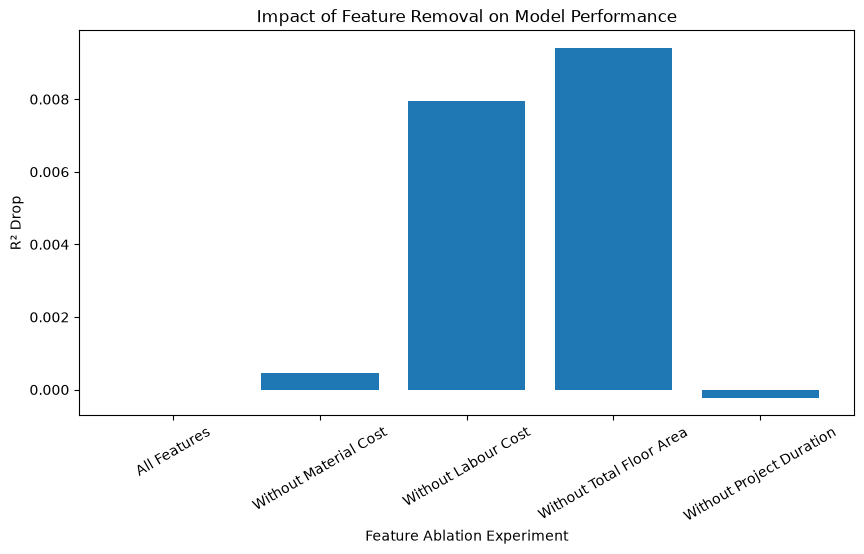

In [83]:
plt.figure(figsize=(10, 5))

plt.bar(
    ablation_results["Experiment"],
    ablation_results["R2_Drop"]
)

plt.ylabel("R² Drop")
plt.xlabel("Feature Ablation Experiment")
plt.title("Impact of Feature Removal on Model Performance")

plt.xticks(rotation=30)

plt.show()

10. Final Findings

In [84]:
final_model_summary = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    
    "Training_R2": [
        0.99410820409847,
        1.0,
        0.9929909401937378
    ],
    
    "Testing_R2": [
        0.9899974069326832,
        0.7383804993903528,
        0.8915750608598545
    ]
})

final_model_summary

,Model,Training_R2,Testing_R2
0,Linear Regression,0.994108,0.989997
1,Decision Tree,1.000000,0.738380
2,Random Forest,0.992991,0.891575


In [85]:
final_model_summary["R2_Gap"] = (
    final_model_summary["Training_R2"]
    - final_model_summary["Testing_R2"]
)

final_model_summary

,Model,Training_R2,Testing_R2,R2_Gap
0,Linear Regression,0.994108,0.989997,0.004111
1,Decision Tree,1.000000,0.738380,0.261620
2,Random Forest,0.992991,0.891575,0.101416


In [86]:
final_performance = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    
    "MAE": [
        0.5975014005854994,
        2.085,
        1.511769999999999
    ],
    
    "RMSE": [
        0.7325222146910104,
        3.746274149071315,
        2.4117322610522076
    ],
    
    "R2": [
        0.9899974069326832,
        0.7383804993903528,
        0.8915750608598545
    ]
})

final_performance

,Model,MAE,RMSE,R2
0,Linear Regression,0.597501,0.732522,0.989997
1,Decision Tree,2.085000,3.746274,0.738380
2,Random Forest,1.511770,2.411732,0.891575


In [87]:
feature_findings = pd.DataFrame({
    "Feature": [
        "Material_Cost_crore_BDT",
        "Labour_Cost_crore_BDT",
        "Total_Floor_Area_sqft",
        "Project_Duration_months",
        "Land_Area_sqft",
        "Number_of_Floors"
    ],
    
    "Importance": [
        0.541430,
        0.196164,
        0.167911,
        0.078967,
        0.005806,
        0.002315
    ]
})

feature_findings

,Feature,Importance
0,Material_Cost_crore_BDT,0.541430
1,Labour_Cost_crore_BDT,0.196164
2,Total_Floor_Area_sqft,0.167911
3,Project_Duration_months,0.078967
4,Land_Area_sqft,0.005806
5,Number_of_Floors,0.002315


In [88]:
print("FINAL FINDINGS")
print("=" * 50)

print("\n1. Model Performance")
print("Linear Regression Test R²:", 0.9899974069326832)
print("Random Forest Test R²:", 0.8915750608598545)
print("Decision Tree Test R²:", 0.7383804993903528)

print("\n2. Overfitting Observation")
print("Decision Tree Training R²:", 1.0)
print("Decision Tree Testing R²:", 0.7383804993903528)

print("\n3. Important Features")
print("Material Cost:", 0.541430)
print("Labour Cost:", 0.196164)
print("Total Floor Area:", 0.167911)

print("\n4. Ablation Observation")
print("Largest R² drop:",
      0.009412,
      "when Total Floor Area was removed.")

FINAL FINDINGS

1. Model Performance
Linear Regression Test R²: 0.9899974069326832
Random Forest Test R²: 0.8915750608598545
Decision Tree Test R²: 0.7383804993903528

2. Overfitting Observation
Decision Tree Training R²: 1.0
Decision Tree Testing R²: 0.7383804993903528

3. Important Features
Material Cost: 0.54143
Labour Cost: 0.196164
Total Floor Area: 0.167911

4. Ablation Observation
Largest R² drop: 0.009412 when Total Floor Area was removed.


11. Limitations

In [89]:
print("Total Projects:", len(df))
print("Training Projects:", len(X_train))
print("Testing Projects:", len(X_test))

Total Projects: 50
Training Projects: 40
Testing Projects: 10


### 11.2 Synthetic Dataset Limitation

This study uses a small synthetic construction project dataset
for demonstrating the machine learning workflow.

Therefore, the observed model performance should not be directly
interpreted as representative of real-world construction projects.

A larger real-world dataset is required to validate the findings.

In [90]:
limitations_summary = pd.DataFrame({
    "Limitation": [
        "Small Dataset",
        "Synthetic Data",
        "Limited Features",
        "Small Test Set",
        "Limited Generalization"
    ],
    
    "Evidence": [
        "50 projects",
        "Synthetic dataset used",
        "Only selected project variables included",
        "10 test projects",
        "Results depend on this dataset and experimental setup"
    ],
    
    "Impact": [
        "May limit model reliability",
        "May not represent real project behavior",
        "Important real-world factors may be missing",
        "Metrics may be sensitive to individual observations",
        "Findings cannot be directly generalized"
    ]
})

limitations_summary

,Limitation,Evidence,Impact
0,Small Dataset,50 projects,May limit model reliability
1,Synthetic Data,Synthetic dataset used,May not represent real project behavior
2,Limited Features,Only selected project variables included,Important real-world factors may be missing
3,Small Test Set,10 test projects,Metrics may be sensitive to individual observa...
4,Limited Generalization,Results depend on this dataset and experimenta...,Findings cannot be directly generalized


## 11. Limitations

This study has several limitations. First, the dataset contains only
50 project observations, which limits the statistical robustness of
the analysis. Second, the dataset is synthetic and therefore may not
fully represent the variability and complexity of real construction
projects.

The study also includes a limited number of project features.
Real-world construction cost may be influenced by additional factors
such as transportation distance, soil conditions, material price
variation, equipment costs, design changes, and project delays.

Furthermore, only 10 observations were used as the final test set.
Therefore, the evaluation metrics may be sensitive to individual
observations.

Finally, the findings should not be directly generalized to real-world
construction projects. Validation using larger and real-world project
datasets is required before drawing broader conclusions.

08_final_analysis.ipynb
│
├── 01. Load Results                 
│
├── 02. Model Performance Comparison
│
├── 03. Actual vs Predicted Analysis
│
├── 04. Error Analysis
│
├── 05. Feature Importance          
│
├── 06. Decision Boundaries      
│
├── 07. Training vs Test / Overfitting  
│
├── 08. Cross Validation                    
│
├── 09. Feature Ablation Experiment    
│
├── 10. Final Findings   
│
├── 11. Limitations  
│
└── 12. Conclusion  ← আজ শুরু

12. Conclusion

## 12. Conclusion

This study explored a machine learning workflow for construction
cost prediction using a small synthetic project dataset.

Three regression models were evaluated: Linear Regression,
Decision Tree, and Random Forest. Among the evaluated models,
Linear Regression achieved the highest test-set R² (0.9900) and
the lowest MAE and RMSE in this experimental dataset.

The Decision Tree achieved a training R² of 1.0000 but its test
R² decreased to 0.7384, indicating a substantial difference
between training and test performance and suggesting overfitting.
Random Forest achieved a test R² of 0.8916 and showed better
test performance than the Decision Tree.

Feature analysis indicated that Material Cost, Labour Cost, and
Total Floor Area were among the most important predictive features
in the Random Forest model. However, feature importance should be
interpreted as model-based predictive importance rather than causal
influence.

Feature ablation experiments showed only small changes in R² when
individual features were removed. This suggests that the predictive
information may be distributed across multiple features in this
small dataset.

Overall, this experiment successfully demonstrated the complete
workflow of a construction cost prediction study, including data
preparation, model development, performance evaluation, error
analysis, feature analysis, overfitting analysis, cross-validation,
and feature ablation.

However, the dataset contains only 50 synthetic project observations.
Therefore, the findings should be considered preliminary and should
not be directly generalized to real-world construction projects.

Future research should use a larger real-world construction dataset,
include additional project-related variables, and evaluate the
models using more robust validation procedures.

### My Research Learning

Through this experiment, I learned that a high training score
does not always mean that a model will perform well on unseen data.

I learned how MAE, RMSE and R² describe model performance from
different perspectives.

I also learned that feature importance does not necessarily mean
causal importance.

The feature ablation experiment helped me understand that removing
one feature does not always cause a large performance drop.

Most importantly, I learned how to question the results instead of
only looking at the highest accuracy.